# 2.2.0 Numpy - přehled

- práce s vícerozměrnými poli (tenzory)
- efektivní operace implementované v C
- interface k operacím lineární algebry
- další funkce ...

[referenční dokumentace](https://numpy.org/doc/stable/)

Další zdroje:
- [NumPy Cheat Sheet](Numpy_Python_Cheat_Sheet.pdf)

- [Stanford lecture](https://web.stanford.edu/~schmit/cme193/lec/lec5.pdf)

- [100 cvičení z Numpy](https://github.com/rougier/numpy-100)

- [Python and SciPy lecture notes](https://hal.inria.fr/hal-01206546/file/ScipyLectures-simple.pdf)

Dále předpokládáme import knihovny ve tvaru:


In [8]:
import numpy as np

# integrovat vystup z matplotlib - statické grafy 
%matplotlib inline

In [3]:
e = np.eye(3)
print(e)

x = np.arange(0,10,1)
print(x)




[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[0 1 2 3 4 5 6 7 8 9]


# 2.2.1 Arrays

- reprezentace N rozměrného tenzoru
- mnohé operace (řezání, transpozice) provádí jen změnu přístupu ke stále stejným datů

In [4]:
# Konverze ze standarnich Pythnonich typu.
list_matrix = [ list(range(3)), list(range(1,4))]
#list_matrix[0][0] = 0.0
print("List matrix:", list_matrix)
a = np.array(list_matrix)
print("Numpy matrix:\n", a, '\npython type:', type(a))

# TODO: zkuste smazat list() na prvnim radku, bude to fungovat. range(..) produkuje sekvenci.

List matrix: [[0, 1, 2], [1, 2, 3]]
Numpy matrix:
 [[0 1 2]
 [1 2 3]] 
python type: <class 'numpy.ndarray'>


### Array - atributy

    a.ndim,  a.shape,  a.size,  a.dtype
   

In [5]:
# Počet dimenzí/os/axis pole
print("ndim", a.ndim)

# Rozměry pole v jednotlivých osách.
print("shape", a.shape)

# Počet prvků pole.
print("size", a.size)

# Type prvků pole (všechny prvky mají stejný typ).
print("dtype", a.dtype)


ndim 2
shape (2, 3)
size 6
dtype int64


Matice `a` má prvky typu `int64`. Numpy automaticky zvolí `int` pokud jsou všechny zadané prvky `int`. Explicitně je možno požadovat jiný typ pomocí parametru `dtype`:

In [6]:
from sys import getsizeof

print("float type:\n", np.array(list_matrix, dtype=float))
print("complex type:\n", np.array(list_matrix, dtype=complex))
print("bool type:\n", np.array(list_matrix, dtype=bool))

# Type variants with different memory footprint.
a8 = np.array(list_matrix, dtype="int8")
print("\nint8 type:\n", a8)
print("element type: ", a8.dtype)

print(f"a  {a.dtype} memory size:", getsizeof(a),)
print("a int 8 memory size:", getsizeof(a8))


float type:
 [[0. 1. 2.]
 [1. 2. 3.]]
complex type:
 [[0.+0.j 1.+0.j 2.+0.j]
 [1.+0.j 2.+0.j 3.+0.j]]
bool type:
 [[False  True  True]
 [ True  True  True]]

int8 type:
 [[0 1 2]
 [1 2 3]]
element type:  int8
a  int64 memory size: 176
a int 8 memory size: 134


### Inicializace array

In [7]:
# sekvence: počátek, konec, krok
print("arange: ", np.arange(1.1, 10, 2.1))

# sekvence: počátek, konec, počet bodů
print("linspace: ", np.linspace(1.1, 10, 4))

# zeros, ones, eye, full
print("zeros :\n", np.zeros((2,4)))
print("ones :\n", np.ones((2,4)))
print("full :\n", np.full((2,4), 3.14))

# jednotkova matice
print("eye :\n", np.eye(4))

arange:  [1.1 3.2 5.3 7.4 9.5]
linspace:  [ 1.1         4.06666667  7.03333333 10.        ]
zeros :
 [[0. 0. 0. 0.]
 [0. 0. 0. 0.]]
ones :
 [[1. 1. 1. 1.]
 [1. 1. 1. 1.]]
full :
 [[3.14 3.14 3.14 3.14]
 [3.14 3.14 3.14 3.14]]
eye :
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


Další funkce pro tvorbu polí viz:

[Numpy doc: array creation routines](https://docs.scipy.org/doc/numpy/reference/routines.array-creation.html)

Pro čtení polí (matic) z textových tabulek lze použít funkci 
- [`np.loadtxt`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.loadtxt.html#numpy.loadtxt).
  EXTRÉMĚ pomalá
- [`pandas.read_csv`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) nejrychlejší  čtení CSV souborů
- [`pandas.read_excel`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_excel.html#pandas.read_excel)
- [`pandas.ExcelWriter`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.ExcelWriter.html#pandas.ExcelWriter)


Vytvoříme si testovací Pandas tabulku = data frame.

In [ ]:
import pandas as pd

dates = pd.date_range('20130101', periods=6)
df = pd.DataFrame(np.random.randn(6, 4), index=dates, columns=list('ABCD'))
df.head()

Vyzkoušíme zápis do Excel souboru a opětovné načtení.
`ExcelWriter` není automaticky součástí Pandas a instaluje se jako samostatný balíček:
    
    pip install xlsxWriter
    
Anaconda má tento balíček již nainstalovaný automaticky.

In [ ]:
with pd.ExcelWriter('ABCD_data.xlsx') as writer:
    df.to_excel(writer)
    
df2 = pd.read_excel('ABCD_data.xlsx')
df2.head()

# 2.2.2 Operace s array

Binární operátory je možné provádět pro dvě pole se stejným `shape`.

In [15]:
a = np.array([[0,1,2], [1,2,3]])
b = np.ones((2,3))
print(a)
print(b)

[[0 1 2]
 [1 2 3]]
[[1. 1. 1.]
 [1. 1. 1.]]


In [ ]:
a + b

In [ ]:
a ** a

In [ ]:
a > b


In [ ]:
# I funkce lze aplikovat po jednotlivých elementech:
np.sin(np.pi * a / 2)

In [ ]:
np.sin([0.1, 1.3])

In [12]:
# funkce z math fungují jen na skalárech
import math

x = np.array([[1]])
print("jednoprvková matice:", x, x.shape)
math.sin(1)
np.sin(1).shape


jednoprvková matice: [[1]] (1, 1)


()

In [ ]:
# Maticove nasobeni @
A = np.array([[0, 1], [2, 3]])
x = np.array([10, 100])
print("A = ", A, "\nx = ", x)
print("A @ x = ", A @ x)
print("np.dot = ", np.dot(A[0], x))
print("np.dot = ", A[0] @ x)
B = np.array([[3, 1], [0, 2]])
print(A @ B) 


### Logaritmická spirála

Příklad použití transformačních matic pro rotaci `R` a škálování `S`.

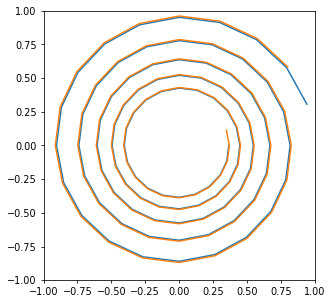

In [13]:
N = 100
theta = 2 * np.pi * 0.05

c, s = np.cos(theta), np.sin(theta)
R = np.array(((c,-s), (s, c)))
S = 0.99 * np.eye(2)
points = np.zeros((N, 2))
x = np.array([1, 0])
for i in range(N):
    x = points[i] = S @ R @ x
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(5,5), dpi=70)
ax.plot(*points.T)
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)


(R @ points[:, :, None]).reshape((N, 2)).T
ax.plot(*(R @ points[:, :, None]).reshape((N, 2)).T)

### Array indexing and slicing
Podpora více indexů najednou v hranatých závorkách pro indexování vícerozměrných polí.

Řez ve formě `[start : end : step]` vybere v jedné dimenzi pouze indexy začínající `start`, s krokem `step` a menší než `end`.

In [19]:
# vstupní matice 2x3
print("matrix A:\n", a, "\n")

# indexování pro vložené listy
a_list = a.tolist()
print(a_list)

# indexovat musím každý list zvlášť
# nefunguje dobře s řezy podle jiného nežli prvního indexu
print("element on row 0, col 1: ", a_list[:][0])
print()
# Více indexů povoleno v rámci jedné vybírací operace
#b=a[:, [0]]
print("first col:\n", a[:, 0] )
a[:, 0] = 10
print(a)

matrix A:
 [[0 1 2]
 [1 2 3]] 

[[0, 1, 2], [1, 2, 3]]
element on row 0, col 1:  [0, 1, 2]

first col:
 [0 1]
[[10  1  2]
 [10  2  3]]


In [ ]:
# Pomocí řezů lze vybírat pod výběry.
# první sloupec
a[:, 0]

In [ ]:
# Druhý řádek, prvky 0..2
a[1, 0:2]

In [ ]:
# Poslední dva prvky druhého řádku
a[1, -2:]

In [ ]:
# První řádek pozpátku.
a[0,::-1]

In [ ]:
# libovolný počet : za sebou, lze napsat jako `...`
# doplní počet : aby naplnil shape 
a[..., 0]

In [21]:
# Konverze vektoru na matici, přidání axis
b=a[0]
print("b= ", b, 'shape', b.shape)

b1 = b[None, :]
print("\n row vector: ", b1, " shape:", b1.shape)

b2 = b[:, np.newaxis]
print("\ncol vector: \n", b2, " shape:", b2.shape)

b=  [10  1  2] shape (3,)

 row vector:  [[10  1  2]]  shape: (1, 3)

col vector: 
 [[10]
 [ 1]
 [ 2]]  shape: (3, 1)


In [22]:
# index 
a = np.arange(10)[:, None] * np.arange(3) 
print(a)
mask = a[:, :] == 2.0
coords = np.arange(a.shape[0])[:, None] * np.arange(a.shape[1]) 
print(coords)

[[ 0  0  0]
 [ 0  1  2]
 [ 0  2  4]
 [ 0  3  6]
 [ 0  4  8]
 [ 0  5 10]
 [ 0  6 12]
 [ 0  7 14]
 [ 0  8 16]
 [ 0  9 18]]
[[ 0  0  0]
 [ 0  1  2]
 [ 0  2  4]
 [ 0  3  6]
 [ 0  4  8]
 [ 0  5 10]
 [ 0  6 12]
 [ 0  7 14]
 [ 0  8 16]
 [ 0  9 18]]


In [23]:
# automatická konverze na větší matice ...broadcasting
a = np.array([[0,1,2], [1,2,3]])
c = np.array([100,200,300])
print("a:", a.shape)
print("c:",c.shape)
a + c

a: (2, 3)
c: (3,)


array([[100, 201, 302],
       [101, 202, 303]])

In [ ]:
a + c[np.newaxis, :]

In [24]:
# non-compatible arrays, non-broad-castable
c = np.array([100, 200])
print("a=", a)
print("c=", c)
a + c

a= [[0 1 2]
 [1 2 3]]
c= [100 200]


ValueError: operands could not be broadcast together with shapes (2,3) (2,) 

In [ ]:
# Explicit broad casting
a + c[:, None]

### Broadcasting
Pokud operandy nemají stejný tvar, je možno operaci provést pokud lze jeden operand rozšířit na shape druhého operandu:
1. Operand s nižším `ndim` se zleva doplní dimenzemi s rozměrem 1 do počtu dimenzí druhého operandu.
2. Pokud v některé dimenzi je rozměr jednoho operandu N a rozměr druhého 1. Druhý operand se v této ose použije N krát.

Obecná pravidla konverze polí menší dimenze na pole vyšší dimenze při (binárních) operacích:

[Numpy broadcasting](https://docs.scipy.org/doc/numpy-1.13.0/reference/ufuncs.html#broadcasting)

In [ ]:
# Nejjednodušší příklad, násobení skalárem
b = 2 * a
b

In [ ]:
# ... je ekvivalentní násobení maticí dvojek.
two = np.full((2,3), 2.0)
two * a

In [26]:
# Broadcasting pro vektor a matici.
a = np.arange(4).reshape((2,2))
print("a matrix:\n", a)
b = np.arange(3,5)
print(b, 'b shape:', b.shape)
bb=b[None, :]
print(bb, 'bb shape:', bb.shape)
bbb = np.concatenate((bb,bb))
print("concat:\n ", bbb)

print("broadcasting: ")
bbb+a

a matrix:
 [[0 1]
 [2 3]]
[3 4] b shape: (2,)
[[3 4]] bb shape: (1, 2)
concat:
  [[3 4]
 [3 4]]
broadcasting: 


array([[3, 5],
       [5, 7]])

In [ ]:
np.ones((4,2)) + np.ones((4,1))

Explicitní broadcasting pomocí `None` indexu. Mnohem lepší srozumitelnost, vnější součin:

In [28]:
a = np.arange(4)
b = np.arange(2,4)
print("a:", a, "b:",b)
# outer product
ba = a[:,None] * b[None, :] 
# transposed outer product
ab = a[None, :] * b[:, None] 
print(ab)
print(ba)

a: [0 1 2 3] b: [2 3]
[[0 2 4 6]
 [0 3 6 9]]
[[0 0]
 [2 3]
 [4 6]
 [6 9]]


In [31]:
# Outer product
a[:, None] @ a[None, :] 

array([[0, 0, 0, 0],
       [0, 1, 2, 3],
       [0, 2, 4, 6],
       [0, 3, 6, 9]])

In [33]:
 a @ a 

np.int64(14)

### Array reshaping

In [34]:
# Rozbalení dat do prostého pole, může být vnitřně realizováno jen pomocí metadat.
# ... vrátí se "view".
a = np.arange(4).reshape((2,2))
print("a: ", a)
b = a.ravel()
b[0] =10
print("po přiřazení do b:\n", "b: ", b)
print("a: ", a)

a:  [[0 1]
 [2 3]]
po přiřazení do b:
 b:  [10  1  2  3]
a:  [[10  1]
 [ 2  3]]


In [35]:
# Stejné dělá metoda flatten, ale nyní vrací kopii skutčeně rozbalených dat. 
a = np.arange(4).reshape((2,2))
print("a: ", a)
b = a.flatten()
b[0] =10
print("po přiřazení do b:\n", "b: ", b)
print("a: ", a)

a:  [[0 1]
 [2 3]]
po přiřazení do b:
 b:  [10  1  2  3]
a:  [[0 1]
 [2 3]]


In [ ]:
# Změna tvaru pomocí přiřazení do attributu shape:
b.shape = (2, 2)
b

In [ ]:
# transpozice
a.T
a.transpose()

np.arange(3)[:, None].T

In [41]:
# Obecná transpozice jak permutace axis.

# Třírozměrný tenzor, osy si označíme pomocí prvků 1,2,3 
xyz  = np.zeros( (2,2,2) )
xyz[0,0,0] = 111
xyz[1,0,0] = 1
xyz[0,1,0] = 2
xyz[0,0,1] = 3

print("\nxyz: \n", xyz)
# Prohodíme první a druhou osu:
print("\ntranspose: \n", xyz.transpose((1,0,2)))
copy_trans = np.array(xyz.transpose((1,0,2)))
copy_trans[0,0,0] = 10
print("copy trans:",copy_trans)
print("xyz:",xyz)


xyz: 
 [[[111.   3.]
  [  2.   0.]]

 [[  1.   0.]
  [  0.   0.]]]

transpose: 
 [[[111.   3.]
  [  1.   0.]]

 [[  2.   0.]
  [  0.   0.]]]
copy trans: [[[10.  3.]
  [ 1.  0.]]

 [[ 2.  0.]
  [ 0.  0.]]]
xyz: [[[111.   3.]
  [  2.   0.]]

 [[  1.   0.]
  [  0.   0.]]]


### Array stacking
Posazení dvou matic (polí) nad sebe, vedle sebe ... 

In [43]:
a= list_matrix =np.array([ list(range(3)), list(range(1,4))])
print(a)
b = 10*a[0]
print(b)

[[0 1 2]
 [1 2 3]]
[ 0 10 20]


In [46]:
display("a", a)
display("b", b)
print("\n")
# Více polí stejného shape na pole vyšší dimenze. 
# Např. z vektorů udělat matici (vektory jako sloupce)
np.stack((a[0], a[1], b), axis=1)

'a'

array([[0, 1, 2],
       [1, 2, 3]])

'b'

array([ 0, 10, 20])

array([[ 0,  1,  0],
       [ 1,  2, 10],
       [ 2,  3, 20]])

In [47]:
# To samé v řádcích
np.stack((a[0], a[1], b))

array([[ 0,  1,  2],
       [ 1,  2,  3],
       [ 0, 10, 20]])

In [50]:
# Více polí různý shape, zachování dimenze. Stejný shape kolmo na axise slučování.
np.concatenate((a, np.array([[10,20]])), axis=0) 
# V axis 0 různá velikost v ostatních axes shoda.

ValueError: all the input array dimensions except for the concatenation axis must match exactly, but along dimension 1, the array at index 0 has size 3 and the array at index 1 has size 2

In [51]:
np.concatenate((a.T, b[:, None]), axis=1) 

array([[ 0,  1,  0],
       [ 1,  2, 10],
       [ 2,  3, 20]])

# 2.2.3 Numpy functions

Get help and try functions:
- min(), max() - return scalar
- minimum(),maximum()  - return array; minimum(A,B) = min(stack(A,B),axis=0)
- average(), mean(), sum(), prod() - return scalar, like min, max
- diff() - first difference, a[1:] - a[:-1]
- dot()
- cumsum(), cumprod()

In [ ]:
a= np.array([[1,2,3],[3,4,5]])
print(a)
          
print("axis 0:", np.sum([[1,2,3],[3,4,5]], axis=0))
print("axis 1:", np.sum([[1,2,3],[3,4,5]], axis=1))


### Linear algebra

In [ ]:
from numpy import linalg as la


## `la` - klíčové funkce

- la.norm()
- la.solve(), la.lu(), la.cholesky(), la.qr()
- la.eig(), la.svd()

np.fft module

In [ ]:
# TODO: vyzkousejte la.eig pro vypoctenou matici P.T @ D @ P.

# Cvičení

## Elipsy
Parametrická rovnice elipsy s poloosami $a$, $b$ je:
        
$$x = a\cos\phi,\quad y = b\sin\phi$$

1. Vypočtěte N bodů na elipse a sestavte je do matice s řádky X a Y.
1. Body zobrazte pomocí `plt.scatter`.
1. Sestavte matici rotace o 45 stupňů:

  $$Rot(\phi) = \begin{bmatrix} \cos\phi & -\sin\phi\\ \sin\phi & \cos\phi\end{bmatrix}$$ 
1. Otočte body na elipse pomocí této matice, zobrazte obě matice do stejného grafu.
1. Zobrazte $k$ takovýchto elips s úhlem otočení $\phi=2\pi i/n$, $k=17$, $N=31$, $a=3$, $b=1$.
  Experimentujte s různými hodnotami.



## Random
1. Nastudujte a vyzkoušejte si základní funkce z modulu np.random:
   
   random, rand, seed, choice
   
2. Vygenerujte:
   
   - náhodnou matici A, shape (3, 3)
   - náhodný vektor b, shape (3, )
   
3. vyřešte soustavu $Ax=b$ a ověřte řešení pomocí výpočtu $Ax - b$

4. Vygenerujte pole dvojic náhodných bodů (úseček) v jednotkovém čtverci, jako matici (N, 2, 2)

5. Vypočtěte pole délek úseček (jednořádkový  kód).

6. Vytvořte pole X, Y, Z, kde X obsahuje x souřednice prvních bodů, Y je y souřadnice prvních bodů, z je logaritmus délek úseček.

7. Vypočtěte průmernou délku úseček a směrodatnou odchylku.

8. Náročnější úkol, působení hmotných bodů: 
    
   1. Vygenerujte náhodné pole bodů v jednotkové krychli a pole náhodných hmotností těchto bodů (libovolně).
   2. Napište funkci, která pro zadaný index $i$. Vypočte sílu kterou na hmotný bod $X_i$ působí ostatní hmotné body:
      
      $$ F_i = \sum_{j\ne i} G \frac{m_i m_j}{|R_{ij}|^3} R_{ij},\quad R_{ij}  =  X_i - X_j$$

In [ ]:
L=la.norm( mat[:,1,:] - mat[:,0,:], axis=1)
X = mat[:, 0, 0]
Z = np.log(L)

In [ ]:
a = np.array([1,2,3])
1.0/np.abs(a[None,:] - a[:, None])